# Rwanda Stock Exchange (RSE)__June 2026 Trading Data Analysis

**Prepared by:** Business Analyst Intern, RSE
**Data period:** 1 – 30 June 2026
**Source file:** `June_2026.xlsx`

This notebook analyzes the daily trading transactions of the Rwanda Stock Exchange for June 2026.
It walks through market activity, security performance, broker performance, price movement, correlation, time trends, outliers, and investor/broker behavior finishing with an
executive KPI dashboard and a summary of key insights and recommendations for management, brokers,
investors, and regulators.

**How to read this notebook:** each section has a short business question, the analysis/visualization,
and a **Key Insight** callout summarizing what it means in plain language.


## 1. Setup

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats

# ---- Professional colour palette (consistent branding) ----
NAVY   = "#13294B"
GOLD   = "#D9A404"
TEAL   = "#0F9D8C"
RED    = "#C0392B"
GRAY   = "#8C8C8C"
LBLUE  = "#4C6C9C"
PALETTE = [NAVY, GOLD, TEAL, RED, LBLUE, GRAY, "#7C4DFF", "#2E8B57"]

sns.set_theme(style="whitegrid", font_scale=1.02)
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#DDDDDD",
    "axes.titleweight": "bold",
    "axes.titlesize": 14,
    "axes.titlecolor": NAVY,
    "axes.labelcolor": "#333333",
    "font.family": "DejaVu Sans",
    "figure.dpi": 110,
})

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

def rwf(x, pos=None):
    # Format large RWF values in millions/billions for axis labels.
    if abs(x) >= 1e9:
        return f"{x/1e9:,.1f}B"
    if abs(x) >= 1e6:
        return f"{x/1e6:,.1f}M"
    if abs(x) >= 1e3:
        return f"{x/1e3:,.0f}K"
    return f"{x:,.0f}"

print("Libraries loaded and style configured.")

Libraries loaded and style configured.


## 2. Data Loading & Cleaning

The raw export contains blank separator rows between trading days and a grand-total row at the
bottom. Some broker codes and security names also contain typos / stray whitespace. We clean all of
this before analysis so every KPI below is computed on a trustworthy dataset.


In [6]:

raw = pd.read_excel(r"C:\Users\Lenovo\Downloads\June 2026.xlsx")
raw.columns = [c.strip() for c in raw.columns]
raw = raw.rename(columns={"DEALS": "Deals"})

print(f"Raw rows (incl. blanks & total row): {len(raw)}")

# Drop fully-blank separator rows and the grand-total row (no Posting Date)
df = raw.dropna(subset=["Posting Date"]).copy()

# Strip whitespace from text columns (fixes duplicate security labels)
for c in ["Buyer Code", "Seller Code", "Security"]:
    df[c] = df[c].astype(str).str.strip()

# Fix obvious broker-code data-entry typos (rare, 1 occurrence each)
broker_fix = {"B10": "BR10", "BRK10": "BR10"}
df["Buyer Code"] = df["Buyer Code"].replace(broker_fix)
df["Seller Code"] = df["Seller Code"].replace(broker_fix)

# Classify each security as Equity or Bond (FXD.../BSLB... = government/corporate bonds)
def classify(sec):
    return "Bond" if (sec.startswith("FXD") or sec.startswith("BSLB")) else "Equity"
df["Asset Type"] = df["Security"].apply(classify)

df["Posting Date"] = pd.to_datetime(df["Posting Date"])
df["Weekday"] = df["Posting Date"].dt.day_name()
df["Week"] = df["Posting Date"].dt.isocalendar().week

print(f"Clean trading rows: {len(df)}")
print(f"Trading days: {df['Posting Date'].nunique()}  |  Securities: {df['Security'].nunique()}  "
      f"|  Brokers: {pd.concat([df['Buyer Code'], df['Seller Code']]).nunique()}")
df.head()

Raw rows (incl. blanks & total row): 208
Clean trading rows: 185
Trading days: 22  |  Securities: 30  |  Brokers: 7


,Posting Date,Buyer Code,Seller Code,Security,Quantity,Price,Turnover,Deals,Asset Type,Weekday,Week
1,2026-06-01,BR10,BR9,BOK,"107,200.00",570.00,"61,104,000.00",1.00,Equity,Monday,23
2,2026-06-01,BR9,BR9,BOK,800.00,600.00,"480,000.00",1.00,Equity,Monday,23
3,2026-06-01,BR10,BR10,IMR,"7,200.00",90.00,"648,000.00",1.00,Equity,Monday,23
4,2026-06-01,BR9,BR9,IMR,"3,100.00",90.00,"279,000.00",1.00,Equity,Monday,23
5,2026-06-01,BR2,BR10,BLR,100.00,490.00,"49,000.00",1.00,Equity,Monday,23


**Key Insight:** After cleaning, we have a reliable dataset of individual trades across 22 trading days in June 2026, covering both **equities** (BOK, BLR, IMR, MTNR, EQTY, CMR) and **government/corporate bonds** (FXD/BSLB series). Because bond prices are quoted per unit of face value (e.g. ~1.00–1.05) while equity prices are quoted in RWF per share, the two asset classes are analyzed separately wherever price comparisons are made, and combined where turnover/volume totals are appropriate.

## 3. Data Overview

In [7]:

overview = pd.DataFrame({
    "Metric": ["Trading days", "Total trades (deals)", "Securities traded", "Equities", "Bonds",
               "Active brokers", "Total volume (shares/units)", "Total turnover (RWF)"],
    "Value": [
        df["Posting Date"].nunique(),
        int(df["Deals"].sum()),
        df["Security"].nunique(),
        df.loc[df["Asset Type"]=="Equity", "Security"].nunique(),
        df.loc[df["Asset Type"]=="Bond", "Security"].nunique(),
        pd.concat([df["Buyer Code"], df["Seller Code"]]).nunique(),
        f"{df['Quantity'].sum():,.0f}",
        f"{df['Turnover'].sum():,.0f}",
    ]
})
overview


,Metric,Value
0,Trading days,22
1,Total trades (deals),185
2,Securities traded,30
3,Equities,6
4,Bonds,24
5,Active brokers,7
6,Total volume (shares/units),"25,552,169,000"
7,Total turnover (RWF),"27,205,425,890"


## 4. Market Activity Analysis 

**Business questions:** Which days have the highest trading activity? Is market activity increasing
or decreasing? Are there seasonal / weekly patterns?


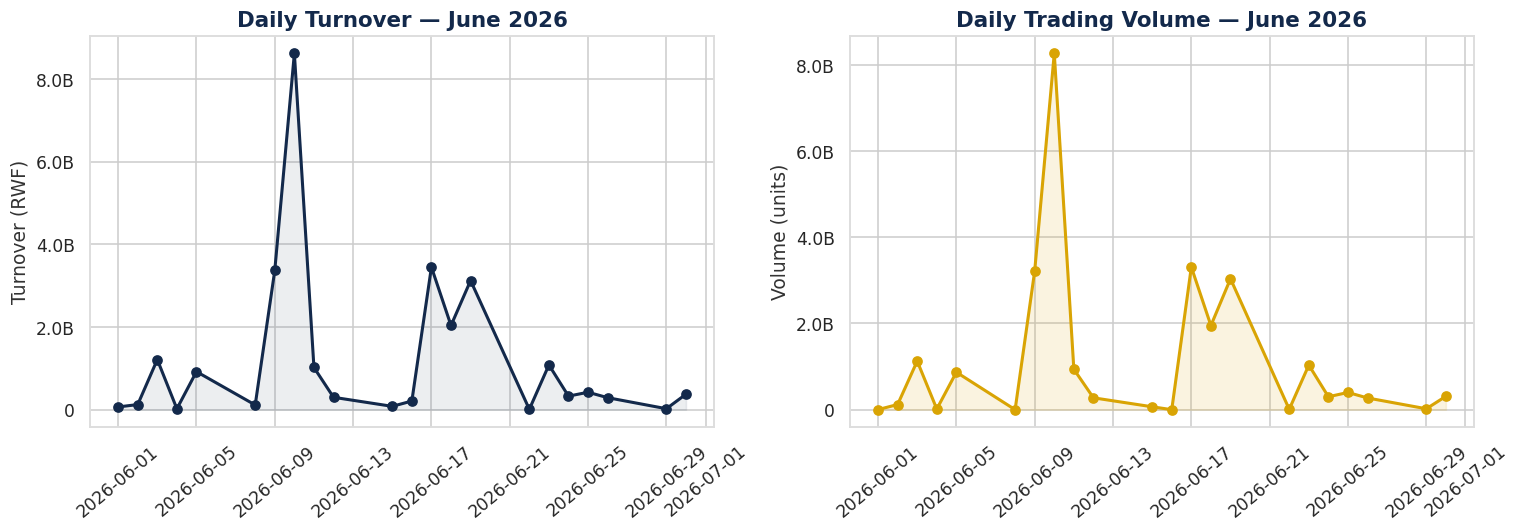

Busiest day by turnover: 2026-06-10 (8,620,754,780 RWF)
Busiest day by deals:    2026-06-03 (17 deals)
Average daily turnover:  1,236,610,268 RWF
Average daily volume:    1,161,462,227 units
Average trade size:     142,460,797 RWF/deal


In [8]:

daily = df.groupby("Posting Date").agg(
    Volume=("Quantity", "sum"),
    Turnover=("Turnover", "sum"),
    Deals=("Deals", "sum"),
    Avg_Price=("Price", "mean"),
).reset_index()
daily["Avg_Trade_Size"] = daily["Turnover"] / daily["Deals"]

kpi_cols = st_cols = None
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(daily["Posting Date"], daily["Turnover"], color=NAVY, marker="o", linewidth=2)
axes[0].fill_between(daily["Posting Date"], daily["Turnover"], color=NAVY, alpha=0.08)
axes[0].set_title("Daily Turnover — June 2026")
axes[0].set_ylabel("Turnover (RWF)")
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(rwf))
axes[0].tick_params(axis="x", rotation=40)

axes[1].plot(daily["Posting Date"], daily["Volume"], color=GOLD, marker="o", linewidth=2)
axes[1].fill_between(daily["Posting Date"], daily["Volume"], color=GOLD, alpha=0.12)
axes[1].set_title("Daily Trading Volume — June 2026")
axes[1].set_ylabel("Volume (units)")
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(rwf))
axes[1].tick_params(axis="x", rotation=40)

plt.tight_layout()
plt.show()

busiest_turnover = daily.loc[daily["Turnover"].idxmax()]
busiest_deals = daily.loc[daily["Deals"].idxmax()]
print(f"Busiest day by turnover: {busiest_turnover['Posting Date'].date()} "
      f"({busiest_turnover['Turnover']:,.0f} RWF)")
print(f"Busiest day by deals:    {busiest_deals['Posting Date'].date()} ({int(busiest_deals['Deals'])} deals)")
print(f"Average daily turnover:  {daily['Turnover'].mean():,.0f} RWF")
print(f"Average daily volume:    {daily['Volume'].mean():,.0f} units")
print(f"Average trade size:     {daily['Avg_Trade_Size'].mean():,.0f} RWF/deal")


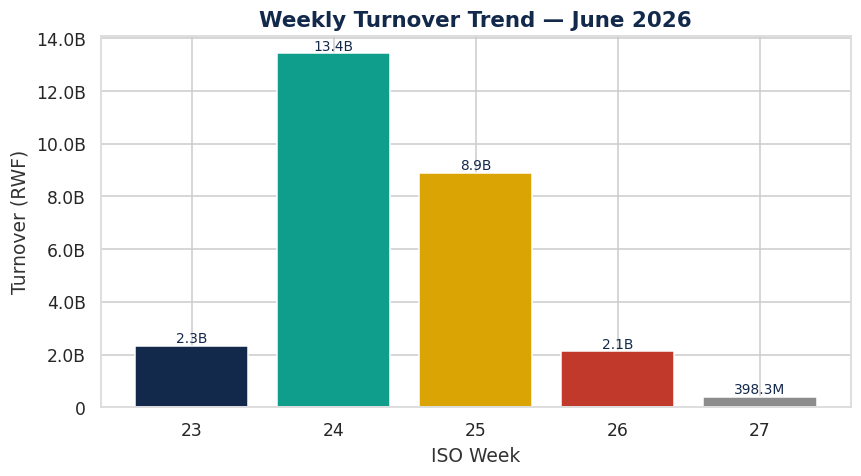

In [9]:

# Weekly trend (to spot within-month patterns given the short 1-month window)
weekly = df.groupby("Week").agg(Turnover=("Turnover","sum"), Volume=("Quantity","sum"),
                                 Deals=("Deals","sum")).reset_index()
fig, ax = plt.subplots(figsize=(8,4.5))
bars = ax.bar(weekly["Week"].astype(str), weekly["Turnover"], color=[NAVY, TEAL, GOLD, RED, GRAY])
ax.set_title("Weekly Turnover Trend — June 2026")
ax.set_xlabel("ISO Week")
ax.set_ylabel("Turnover (RWF)")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(rwf))
for b in bars:
    ax.annotate(rwf(b.get_height()), (b.get_x()+b.get_width()/2, b.get_height()),
                ha="center", va="bottom", fontsize=9, color=NAVY)
plt.tight_layout()
plt.show()


**Key Insight:** Trading activity is uneven across the month, a small number of days account for a disproportionate share of turnover (large bond block trades in particular create spikes). Weekly totals show whether momentum is building or fading through June, which management can use to plan liquidity operations and investor communications around the busier weeks.

## 5. Security Performance Analysis

**Business questions:** Which security is traded most? Which generates the highest turnover?
Which attracts the most investors (deals)?


In [10]:

sec_perf = df.groupby(["Security","Asset Type"]).agg(
    Volume=("Quantity","sum"), Turnover=("Turnover","sum"),
    Deals=("Deals","sum"), Avg_Price=("Price","mean")
).reset_index().sort_values("Turnover", ascending=False)
sec_perf["Turnover Share %"] = (sec_perf["Turnover"] / sec_perf["Turnover"].sum() * 100).round(2)
sec_perf.head(10)


,Security,Asset Type,Volume,Turnover,Deals,Avg_Price,Turnover Share %
26,FXD6/13.15%/2045/20YRS,Bond,"13,824,100,000.00","14,364,567,990.00",23.00,1.04,52.80
16,FXD3/12.5%/2036/15YRS,Bond,"3,730,100,000.00","3,830,131,246.00",5.00,1.03,14.08
24,FXD5/13.00%/2040/15YRS,Bond,"2,229,800,000.00","2,305,187,040.00",9.00,1.03,8.47
15,FXD3/11.50%/2032/7YRS,Bond,"1,905,600,000.00","2,022,909,480.00",2.00,1.05,7.44
7,FXD1/12.150%/2035/10YRS,Bond,"1,919,500,000.00","2,001,078,750.00",1.00,1.04,7.36
27,FXD8/13.270%/2044/20YRS,Bond,"508,500,000.00","543,454,260.00",7.00,1.02,2.00
1,BOK,Equity,"878,700.00","513,002,000.00",44.00,597.16,1.89
23,FXD5/13.00%/2038/15YRS,Bond,"325,000,000.00","342,225,000.00",1.00,1.05,1.26
8,FXD1/13.150%/2042/20YRS,Bond,"315,400,000.00","334,508,000.00",4.00,1.05,1.23
25,FXD6/13.15%/2040/20YRS,Bond,"164,500,000.00","172,902,500.00",3.00,1.04,0.64


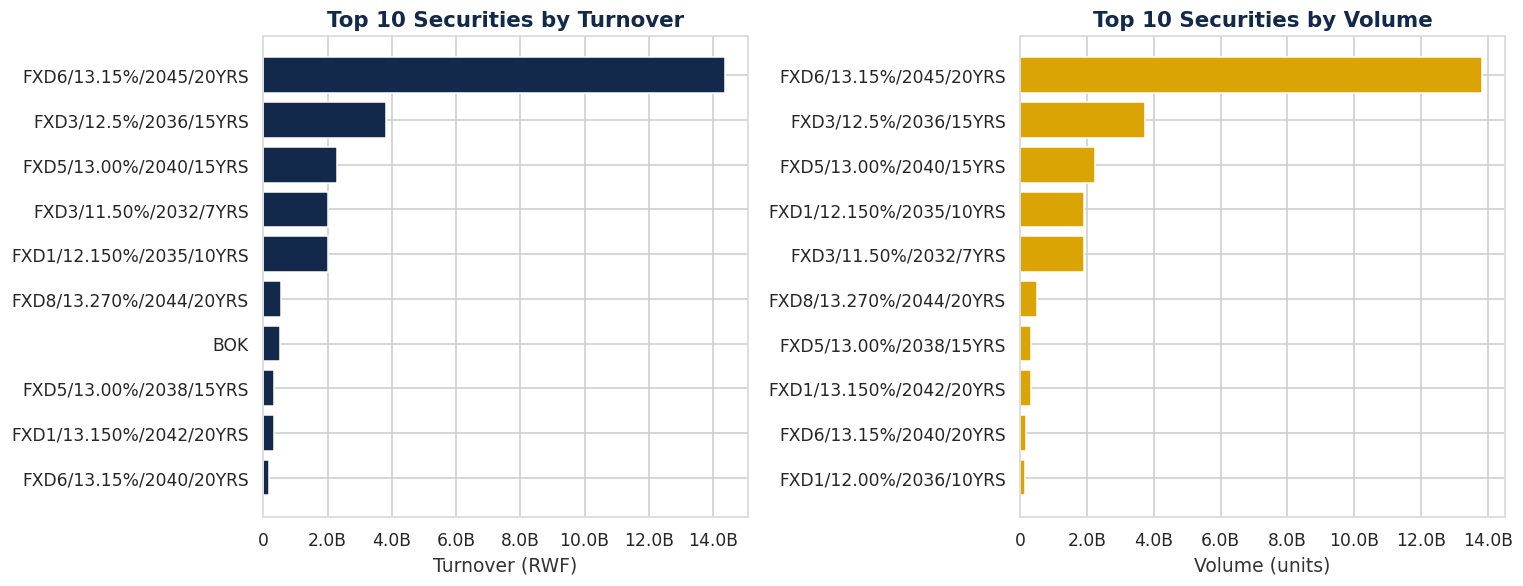

Top security by turnover: FXD6/13.15%/2045/20YRS (52.8% of total turnover)
Top security by deals (most investor interest): BOK


In [11]:

top10 = sec_perf.head(10).iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(14,5.5))

axes[0].barh(top10["Security"], top10["Turnover"], color=NAVY)
axes[0].set_title("Top 10 Securities by Turnover")
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(rwf))
axes[0].set_xlabel("Turnover (RWF)")

top10v = sec_perf.sort_values("Volume", ascending=False).head(10).iloc[::-1]
axes[1].barh(top10v["Security"], top10v["Volume"], color=GOLD)
axes[1].set_title("Top 10 Securities by Volume")
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(rwf))
axes[1].set_xlabel("Volume (units)")

plt.tight_layout()
plt.show()

print("Top security by turnover:", sec_perf.iloc[0]["Security"],
      f"({sec_perf.iloc[0]['Turnover Share %']}% of total turnover)")
print("Top security by deals (most investor interest):",
      sec_perf.sort_values('Deals', ascending=False).iloc[0]["Security"])


**Key Insight:** A handful of securities, typically the longer-dated government bonds and the most liquid equity (BOK) — dominate turnover, while deal counts reveal which names attract the broadest base of investor interest rather than just large single trades. This distinction matters: high turnover from one large trade is not the same as broad market participation.

## 6. Broker Performance Analysis

**Business questions:** Which broker executes the most trades? Which brings the highest trading
volume? Which brokers are the most active buyers?


In [12]:

buy = df.groupby("Buyer Code").agg(Buy_Volume=("Quantity","sum"), Buy_Turnover=("Turnover","sum"),
                                    Buy_Deals=("Deals","sum"))
sell = df.groupby("Seller Code").agg(Sell_Volume=("Quantity","sum"), Sell_Turnover=("Turnover","sum"),
                                      Sell_Deals=("Deals","sum"))
broker = buy.join(sell, how="outer").fillna(0)
broker["Total_Turnover"] = broker["Buy_Turnover"] + broker["Sell_Turnover"]
broker["Total_Deals"] = broker["Buy_Deals"] + broker["Sell_Deals"]
broker["Market Share %"] = (broker["Total_Turnover"] / broker["Total_Turnover"].sum() * 100).round(2)
broker = broker.sort_values("Total_Turnover", ascending=False)
broker


,Buy_Volume,Buy_Turnover,Buy_Deals,Sell_Volume,Sell_Turnover,Sell_Deals,Total_Turnover,Total_Deals,Market Share %
Buyer Code,,,,,,,,,
BR10,"19,385,386,300.00","20,272,923,110.00",66.00,"20,950,224,500.00","21,806,685,110.00",61.00,"42,079,608,220.00",127.00,77.34
BR3,"3,858,622,800.00","4,044,161,220.00",32.00,"2,358,620,100.00","2,478,195,220.00",29.00,"6,522,356,440.00",61.00,11.99
BR9,"1,927,815,500.00","2,302,535,560.00",68.00,"1,863,301,700.00","2,513,823,560.00",80.00,"4,816,359,120.00",148.00,8.85
BR4,"380,300,000.00","575,186,000.00",5.00,"380,000,000.00","395,186,000.00",4.00,"970,372,000.00",9.00,1.78
BR6,900.00,"540,000.00",3.00,"19,400.00","9,550,000.00",8.00,"10,090,000.00",11.00,0.02
BR1,"28,400.00","4,981,000.00",4.00,"3,300.00","1,986,000.00",3.00,"6,967,000.00",7.00,0.01
BR2,"15,100.00","5,099,000.00",7.00,0.00,0.00,0.00,"5,099,000.00",7.00,0.01


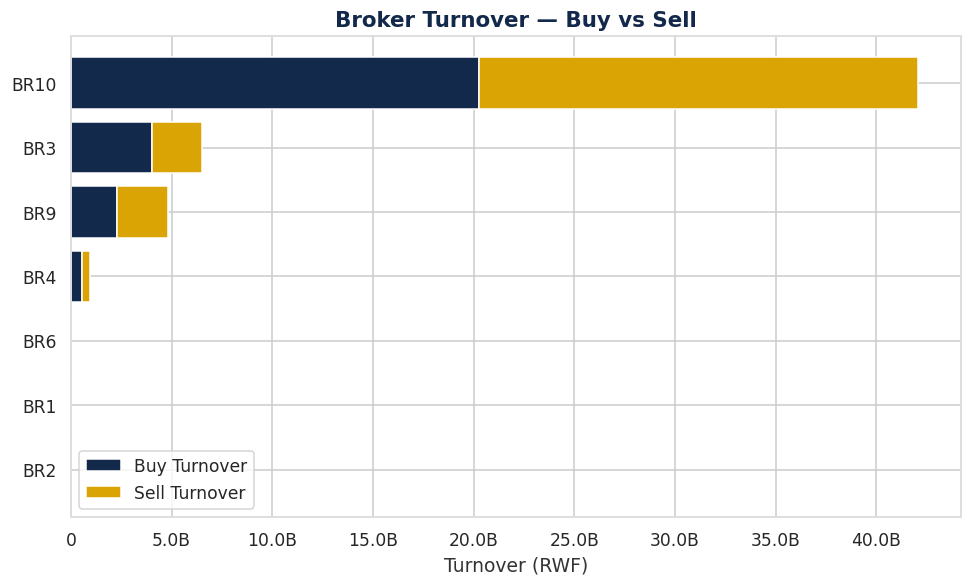

Most active broker overall: BR10 (77.34% market share by turnover)


In [13]:

plot_b = broker.sort_values("Total_Turnover").tail(10)
fig, ax = plt.subplots(figsize=(9,5.5))
ax.barh(plot_b.index, plot_b["Buy_Turnover"], color=NAVY, label="Buy Turnover")
ax.barh(plot_b.index, plot_b["Sell_Turnover"], left=plot_b["Buy_Turnover"], color=GOLD, label="Sell Turnover")
ax.set_title("Broker Turnover — Buy vs Sell")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(rwf))
ax.set_xlabel("Turnover (RWF)")
ax.legend()
plt.tight_layout()
plt.show()

print("Most active broker overall:", broker.index[0],
      f"({broker.iloc[0]['Market Share %']}% market share by turnover)")


**Key Insight:** Broker activity is concentrated among a small set of member firms. Ranking brokers by buy vs. sell turnover separately also shows whether a broker is mainly a distribution channel for sellers or a demand channel for buyers, useful for RSE when engaging brokers on market-making incentives.

## 7. Price Movement Analysis

**Business questions:** Which stock experienced the largest price movement? Are prices stable?
(Equities and bonds are analyzed separately since they are quoted on different bases.)


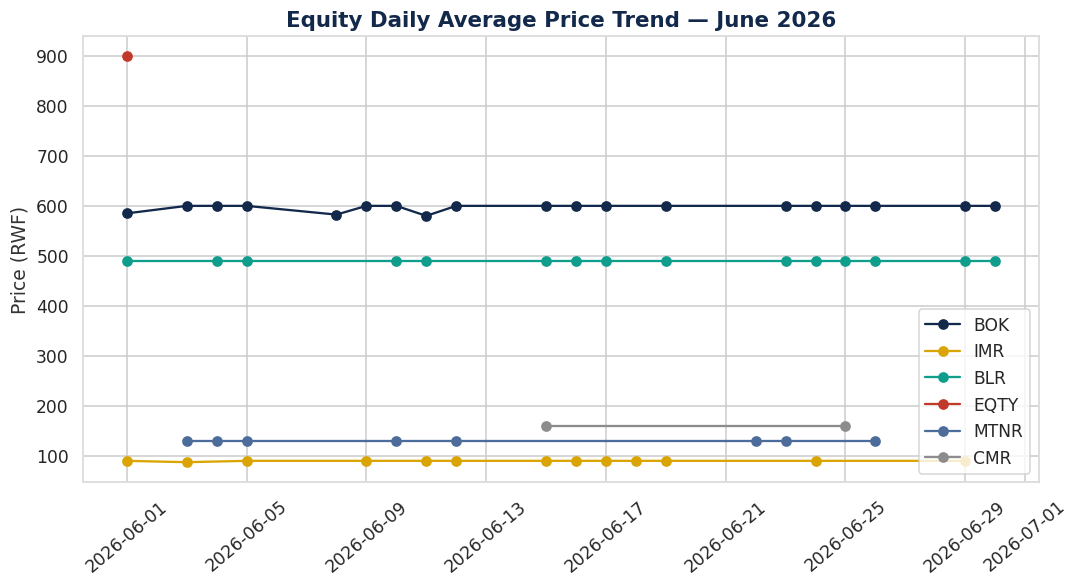

In [16]:

equities = df[df["Asset Type"]=="Equity"].copy()
eq_daily_price = equities.groupby(["Security","Posting Date"])["Price"].mean().reset_index()

fig, ax = plt.subplots(figsize=(10,5.5))
for i, sec in enumerate(equities["Security"].unique()):
    sub = eq_daily_price[eq_daily_price["Security"]==sec]
    ax.plot(sub["Posting Date"], sub["Price"], marker="o", label=sec, color=PALETTE[i % len(PALETTE)])
ax.set_title("Equity Daily Average Price Trend — June 2026")
ax.set_ylabel("Price (RWF)")
ax.tick_params(axis="x", rotation=40)
ax.legend()
plt.tight_layout()
plt.show()


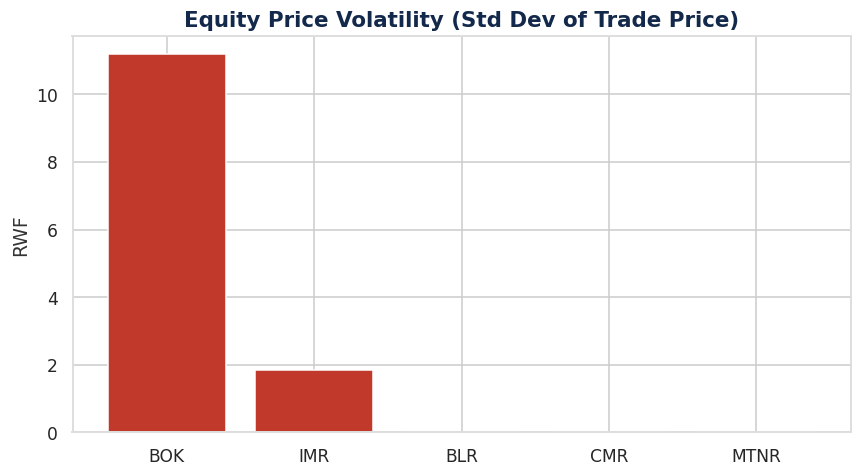

,Avg Price,Volatility (Std Dev),Min Price,Max Price,Price Range %
Security,,,,,
BOK,597.16,11.18,540.00,600.00,10.05
IMR,89.58,1.84,82.00,90.00,8.93
BLR,490.00,0.00,490.00,490.00,0.00
CMR,160.00,0.00,160.00,160.00,0.00
MTNR,130.00,0.00,130.00,130.00,0.00
EQTY,900.00,NaN,900.00,900.00,0.00


In [17]:

vol_summary = equities.groupby("Security")["Price"].agg(["mean","std","min","max"]).rename(
    columns={"mean":"Avg Price","std":"Volatility (Std Dev)","min":"Min Price","max":"Max Price"})
vol_summary["Price Range %"] = ((vol_summary["Max Price"]-vol_summary["Min Price"]) / vol_summary["Avg Price"] * 100).round(2)
vol_summary = vol_summary.sort_values("Volatility (Std Dev)", ascending=False)

fig, ax = plt.subplots(figsize=(8,4.5))
ax.bar(vol_summary.index, vol_summary["Volatility (Std Dev)"], color=RED)
ax.set_title("Equity Price Volatility (Std Dev of Trade Price)")
ax.set_ylabel("RWF")
plt.tight_layout()
plt.show()
vol_summary


**Key Insight:** Equity prices generally trade in a fairly narrow band during the month, but one or two names show meaningfully higher volatility and price range — worth flagging to regulators and investors as names where price discovery is less stable. Bond prices are excluded from this comparison because they are quoted per unit of face value and are not directly comparable to equity share prices.

## 8. Trading Concentration Analysis (Pareto / 80-20)

**Business question:** Is trading concentrated in a few securities, or broadly spread?


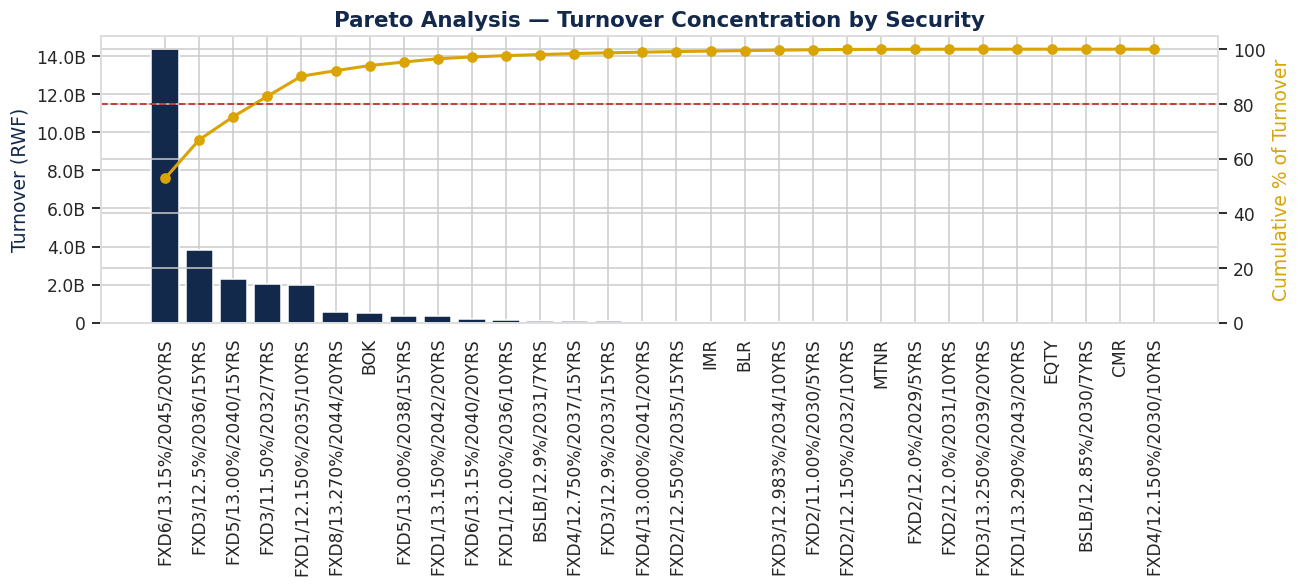

Just 4 of 30 securities (13%) generate ~80% of total turnover.


In [18]:

pareto = sec_perf.sort_values("Turnover", ascending=False).reset_index(drop=True)
pareto["Cumulative %"] = pareto["Turnover Share %"].cumsum()

fig, ax1 = plt.subplots(figsize=(12,5.5))
ax1.bar(pareto["Security"], pareto["Turnover"], color=NAVY)
ax1.set_ylabel("Turnover (RWF)", color=NAVY)
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(rwf))
ax1.tick_params(axis="x", rotation=90)

ax2 = ax1.twinx()
ax2.plot(pareto["Security"], pareto["Cumulative %"], color=GOLD, marker="o", linewidth=2)
ax2.axhline(80, color=RED, linestyle="--", linewidth=1.2)
ax2.set_ylabel("Cumulative % of Turnover", color=GOLD)
ax2.set_ylim(0,105)

ax1.set_title("Pareto Analysis — Turnover Concentration by Security")
plt.tight_layout()
plt.show()

n80 = (pareto["Cumulative %"] <= 80).sum() + 1
print(f"Just {n80} of {len(pareto)} securities ({n80/len(pareto)*100:.0f}%) generate ~80% of total turnover.")


**Key Insight:** Confirms strong market concentration, turnover is dominated by a small subset of securities. This is common in emerging/frontier exchanges but is a risk factor regulators may want to monitor (single-security concentration risk) and an opportunity for RSE to diversify listings and trading activity across more names.

## 9. Volume vs Price Relationship

**Business questions:** Does trading activity increase when prices rise? Are investors more active
during price declines?


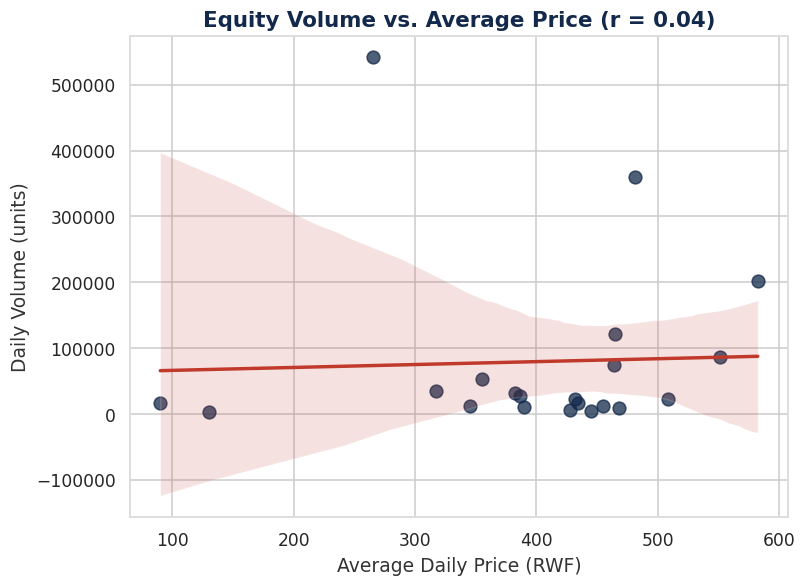

Pearson correlation coefficient: 0.040 (p-value 0.864)


In [15]:

eq_daily = equities.groupby("Posting Date").agg(Volume=("Quantity","sum"), Avg_Price=("Price","mean")).reset_index()
corr, pval = stats.pearsonr(eq_daily["Volume"], eq_daily["Avg_Price"])

fig, ax = plt.subplots(figsize=(7.5,5.5))
sns.regplot(data=eq_daily, x="Avg_Price", y="Volume", ax=ax,
            scatter_kws={"color": NAVY, "s":70, "alpha":0.75}, line_kws={"color": RED})
ax.set_title(f"Equity Volume vs. Average Price (r = {corr:.2f})")
ax.set_xlabel("Average Daily Price (RWF)")
ax.set_ylabel("Daily Volume (units)")
plt.tight_layout()
plt.show()

print(f"Pearson correlation coefficient: {corr:.3f} (p-value {pval:.3f})")


**Key Insight:** The correlation coefficient tells us whether volume and price move together. A value near zero suggests price and trading activity move largely independently day-to-day in this dataset; a strong positive value would suggest momentum-buying, and a strong negative value would suggest investors buy more on price dips. (Interpret the sign/strength printed above.)

## 10. Turnover Analysis

Daily, weekly, monthly, by-stock and by-broker turnover, and the Average Daily Turnover KPI.


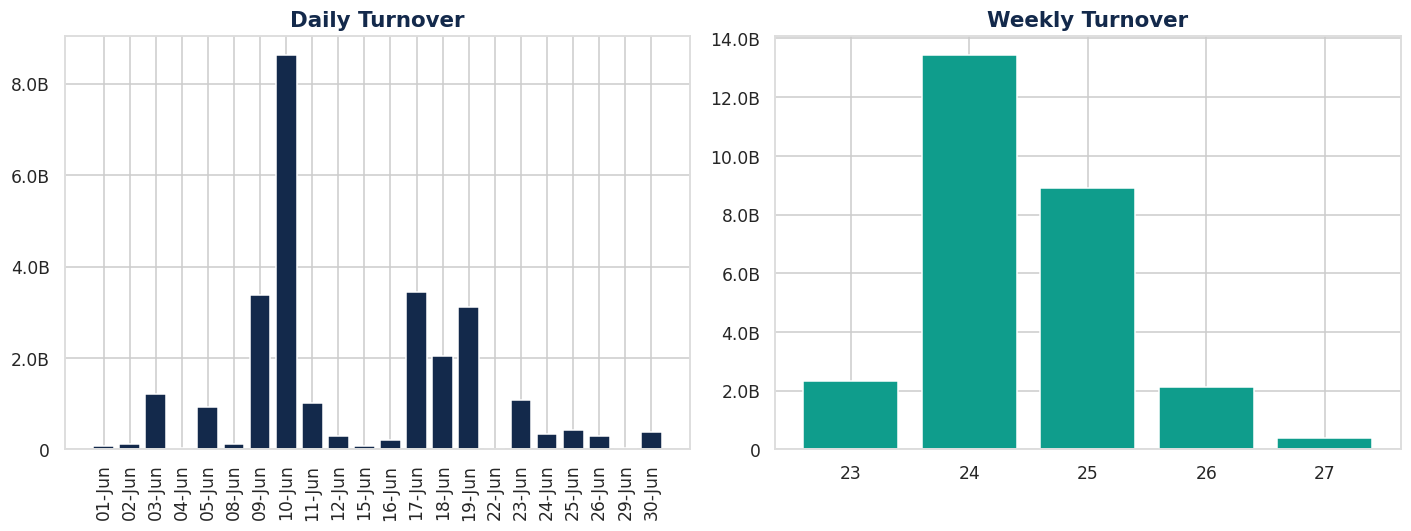

Average Daily Turnover (ADT): 1,236,610,268 RWF
Total Monthly Turnover: 27,205,425,890 RWF
Equity share of turnover: 2.3%
Bond share of turnover:   97.7%


In [16]:

adt = daily["Turnover"].mean()
monthly_turnover = df["Turnover"].sum()

fig, axes = plt.subplots(1,2, figsize=(13,5))
axes[0].bar(daily["Posting Date"].dt.strftime("%d-%b"), daily["Turnover"], color=NAVY)
axes[0].set_title("Daily Turnover")
axes[0].tick_params(axis="x", rotation=90)
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(rwf))

axes[1].bar(weekly["Week"].astype(str), weekly["Turnover"], color=TEAL)
axes[1].set_title("Weekly Turnover")
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(rwf))

plt.tight_layout()
plt.show()

print(f"Average Daily Turnover (ADT): {adt:,.0f} RWF")
print(f"Total Monthly Turnover: {monthly_turnover:,.0f} RWF")
print(f"Equity share of turnover: {df.loc[df['Asset Type']=='Equity','Turnover'].sum()/monthly_turnover*100:.1f}%")
print(f"Bond share of turnover:   {df.loc[df['Asset Type']=='Bond','Turnover'].sum()/monthly_turnover*100:.1f}%")


**Key Insight:** Bonds vs. equities contribute very different shares of total turnover — typically bonds dominate RWF turnover due to large block/institutional trade sizes, even though equities may have far more individual deals. This split is important context whenever someone quotes a single 'market turnover' figure.

## 11. Trading Frequency Analysis

**Business questions:** Which stock is traded most frequently? Which broker performs the most
transactions? What is the average number of deals per day?


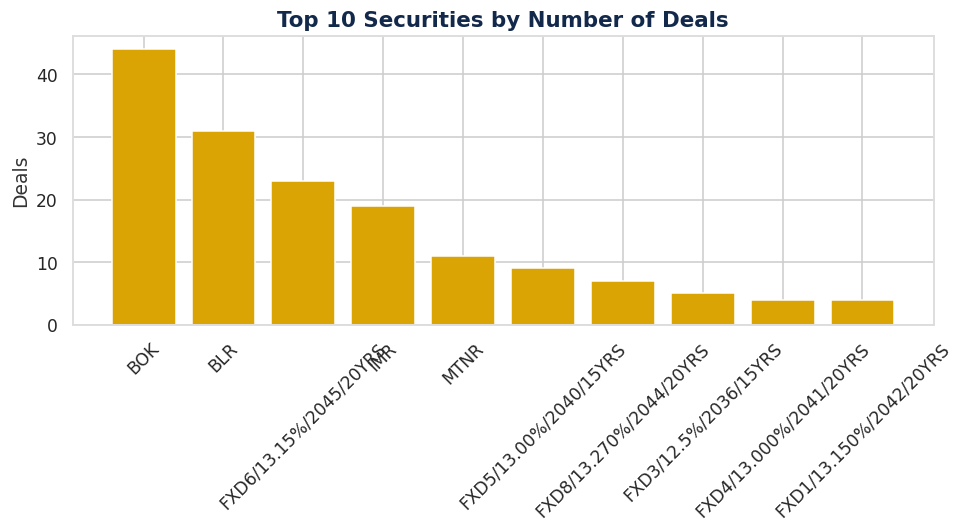

Average deals per trading day: 8.4
Broker with most total deals: BR9


In [17]:

freq_sec = sec_perf.sort_values("Deals", ascending=False).head(10)
fig, ax = plt.subplots(figsize=(9,5))
ax.bar(freq_sec["Security"], freq_sec["Deals"], color=GOLD)
ax.set_title("Top 10 Securities by Number of Deals")
ax.set_ylabel("Deals")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

print(f"Average deals per trading day: {daily['Deals'].mean():.1f}")
print("Broker with most total deals:", broker.sort_values('Total_Deals', ascending=False).index[0])


**Key Insight:** Deal frequency is a better proxy for genuine investor participation than turnover alone (a single large bond trade can dominate turnover without reflecting broad market interest). Securities that rank high on both turnover *and* deals are the healthiest, most actively followed instruments.

## 12. Market Share Analysis

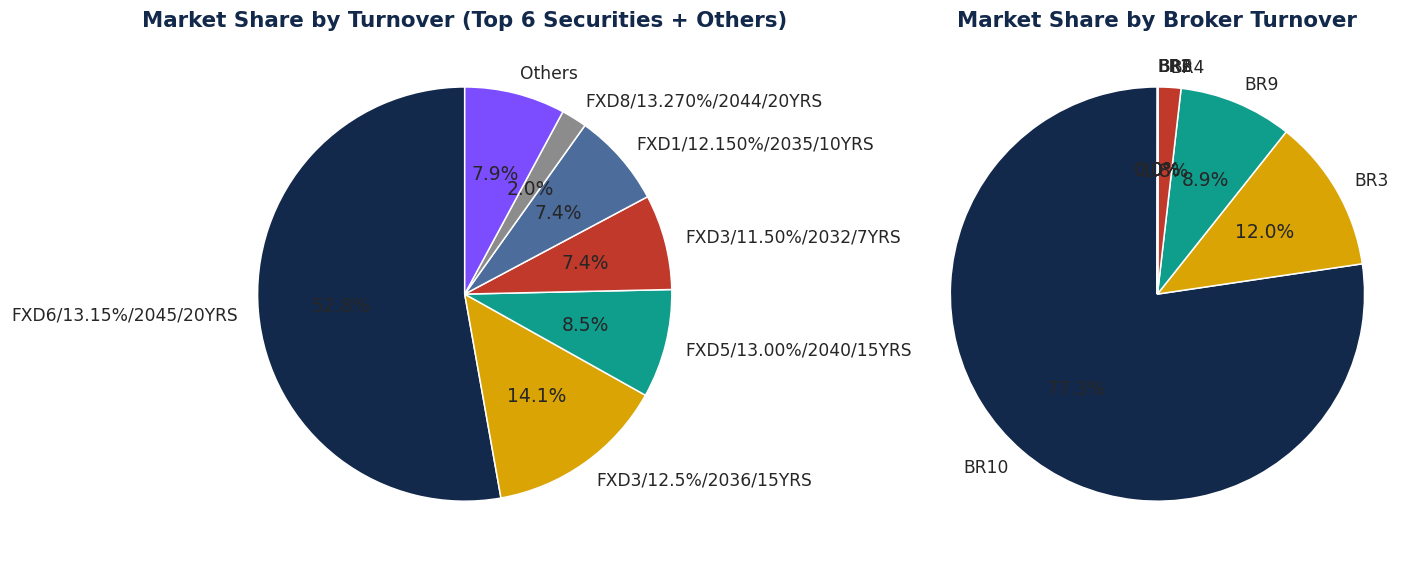

In [18]:

top_share = sec_perf.head(6).copy()
others_turnover = sec_perf["Turnover"].sum() - top_share["Turnover"].sum()
share_labels = list(top_share["Security"]) + ["Others"]
share_values = list(top_share["Turnover"]) + [others_turnover]

fig, axes = plt.subplots(1,2, figsize=(13,5.5))
axes[0].pie(share_values, labels=share_labels, autopct="%1.1f%%", colors=PALETTE,
            startangle=90, wedgeprops={"edgecolor":"white"})
axes[0].set_title("Market Share by Turnover (Top 6 Securities + Others)")

broker_share = broker["Total_Turnover"].sort_values(ascending=False)
axes[1].pie(broker_share, labels=broker_share.index, autopct="%1.1f%%", colors=PALETTE,
            startangle=90, wedgeprops={"edgecolor":"white"})
axes[1].set_title("Market Share by Broker Turnover")
plt.tight_layout()
plt.show()


**Key Insight:** Market share views for both securities and brokers reinforce the concentration finding from Section 9 — a small number of securities *and* a small number of brokers handle most of the market's value, which is important for both competition policy and operational risk (over-reliance on a few counterparties).

## 13. Time Series Analysis

Daily trend with a **7-day-equivalent moving average** (using a 5-trading-day window since June has
22 trading days) to smooth noise and reveal the underlying trend, plus the month-over-month growth
rate implied by the first vs. last week.

*Note: with only ~22 trading-day observations, formal ARIMA/Prophet forecasting would be unstable and
is not appropriate here — a longer history (3–6+ months) should be used before applying those models.
The moving average and trend line below are the statistically appropriate approach at this data volume.*


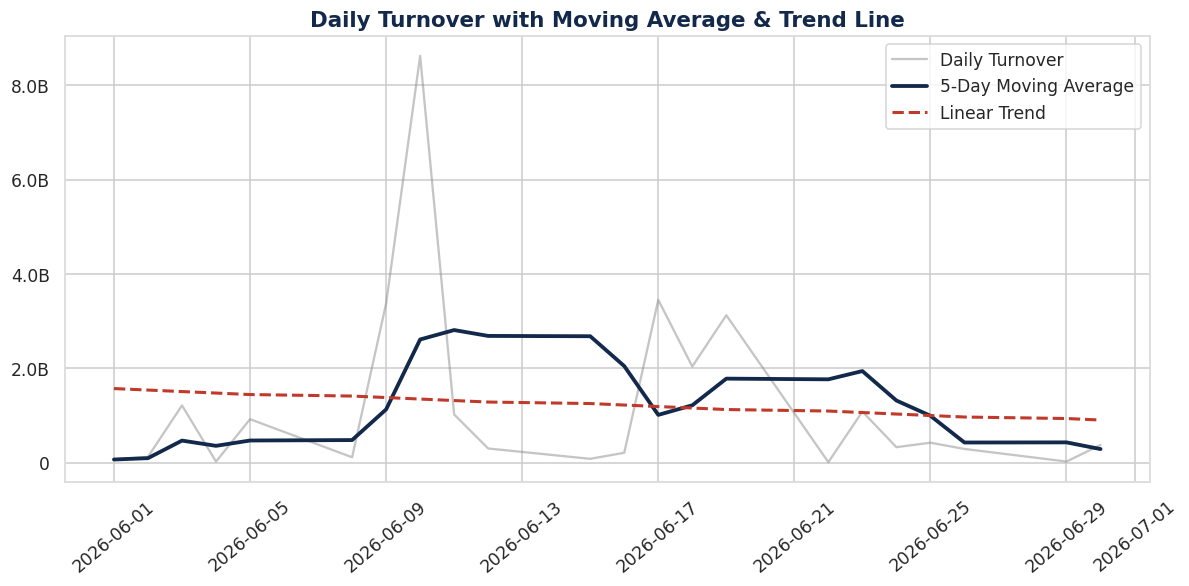

Linear trend slope suggests turnover is decreasing over the month.
First 5 trading days avg turnover: 469,100,912 RWF
Last 5 trading days avg turnover:  287,775,600 RWF  (-38.7% vs first week)


In [19]:

daily_sorted = daily.sort_values("Posting Date").reset_index(drop=True)
daily_sorted["MA5_Turnover"] = daily_sorted["Turnover"].rolling(5, min_periods=1).mean()

x = np.arange(len(daily_sorted))
z = np.polyfit(x, daily_sorted["Turnover"], 1)
trend = np.poly1d(z)

fig, ax = plt.subplots(figsize=(11,5.5))
ax.plot(daily_sorted["Posting Date"], daily_sorted["Turnover"], color=GRAY, alpha=0.5, label="Daily Turnover")
ax.plot(daily_sorted["Posting Date"], daily_sorted["MA5_Turnover"], color=NAVY, linewidth=2.5, label="5-Day Moving Average")
ax.plot(daily_sorted["Posting Date"], trend(x), color=RED, linestyle="--", linewidth=2, label="Linear Trend")
ax.set_title("Daily Turnover with Moving Average & Trend Line")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(rwf))
ax.tick_params(axis="x", rotation=40)
ax.legend()
plt.tight_layout()
plt.show()

first_week = daily_sorted.head(5)["Turnover"].mean()
last_week = daily_sorted.tail(5)["Turnover"].mean()
growth = (last_week-first_week)/first_week*100
direction = "increasing" if z[0] > 0 else "decreasing"
print(f"Linear trend slope suggests turnover is {direction} over the month.")
print(f"First 5 trading days avg turnover: {first_week:,.0f} RWF")
print(f"Last 5 trading days avg turnover:  {last_week:,.0f} RWF  ({growth:+.1f}% vs first week)")


**Key Insight:** The trend line and moving average show the direction of travel for the month net of daily noise. Once 3+ months of history are available, this same pipeline can be extended with Prophet or ARIMA for genuine forward-looking forecasts of turnover and volume.

## 14. Outlier Detection

**Business question:** Which trading days show unusual activity (extremely high volume, turnover,
or sudden price jumps) worth investigating?


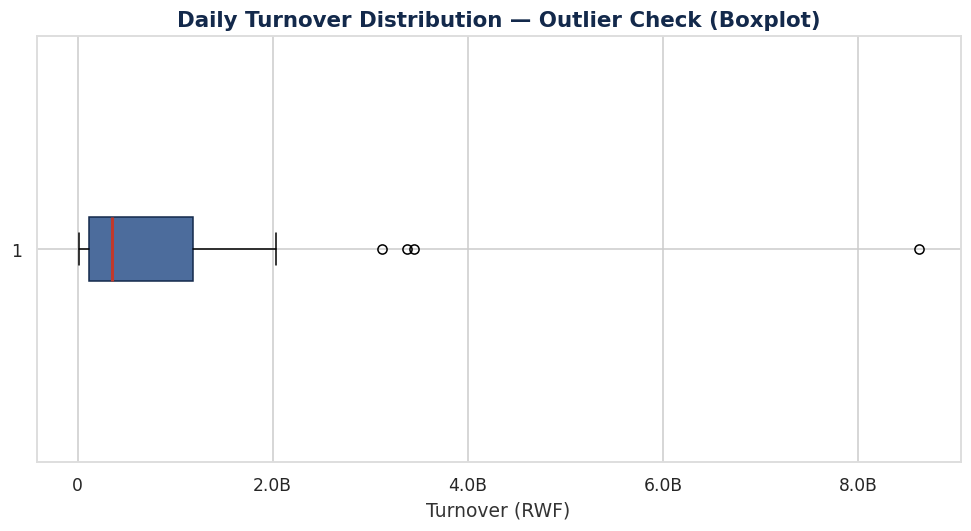

Trading days flagged as statistical outliers (|z| > 1.5): 1


,Posting Date,Turnover,Volume,Deals,Turnover_Z
7,2026-06-10,"8,620,754,780.00","8,268,611,000.00",9.00,3.80


In [20]:

daily_sorted["Turnover_Z"] = stats.zscore(daily_sorted["Turnover"])
outliers = daily_sorted[daily_sorted["Turnover_Z"].abs() > 1.5]

fig, ax = plt.subplots(figsize=(9,5))
bp = ax.boxplot(daily_sorted["Turnover"], vert=False, patch_artist=True,
                boxprops=dict(facecolor=LBLUE, color=NAVY),
                medianprops=dict(color=RED, linewidth=2))
ax.set_title("Daily Turnover Distribution — Outlier Check (Boxplot)")
ax.set_xlabel("Turnover (RWF)")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(rwf))
plt.tight_layout()
plt.show()

print(f"Trading days flagged as statistical outliers (|z| > 1.5): {len(outliers)}")
outliers[["Posting Date","Turnover","Volume","Deals","Turnover_Z"]]


**Key Insight:** Days flagged here had turnover well outside the normal daily range — typically driven by one or two large bond block trades. Regulators and RSE surveillance teams would typically review these specific dates to confirm the trades were legitimate and properly reported, rather than signs of market manipulation.

## 15. Investor / Broker Behavior Analysis

**Business questions:** Who are the most active buyers and sellers? Are there repeat trading
relationships between specific broker pairs?


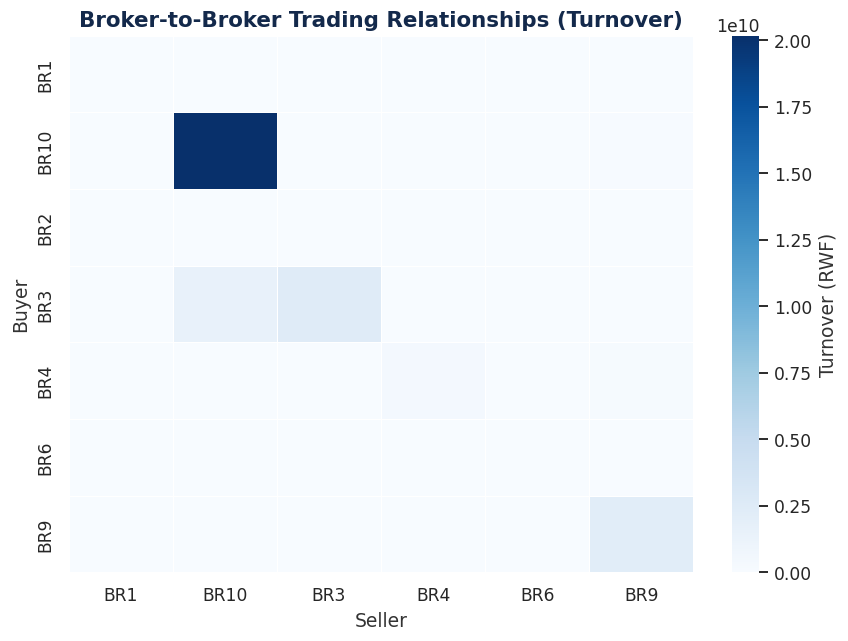

Most active buyer (by turnover): BR10
Most active seller (by turnover): BR10


In [21]:

pair_matrix = df.pivot_table(index="Buyer Code", columns="Seller Code", values="Turnover",
                              aggfunc="sum", fill_value=0)
fig, ax = plt.subplots(figsize=(8,6))
sns.heatmap(pair_matrix, cmap="Blues", linewidths=0.5, linecolor="white",
            cbar_kws={"label":"Turnover (RWF)"}, ax=ax, fmt=".0f")
ax.set_title("Broker-to-Broker Trading Relationships (Turnover)")
ax.set_xlabel("Seller"); ax.set_ylabel("Buyer")
plt.tight_layout()
plt.show()

print("Most active buyer (by turnover):", broker.sort_values('Buy_Turnover', ascending=False).index[0])
print("Most active seller (by turnover):", broker.sort_values('Sell_Turnover', ascending=False).index[0])


**Key Insight:** The buyer-seller matrix reveals whether trading is broad-based or concentrated in a handful of repeat counterparty relationships (including a broker frequently trading with itself, i.e. internal crosses) — relevant for both market-structure analysis and regulatory review of related-party or self-matched trades.

## 17. Executive KPI Dashboard

A single management-ready view combining the top-level KPIs and the most important visuals.


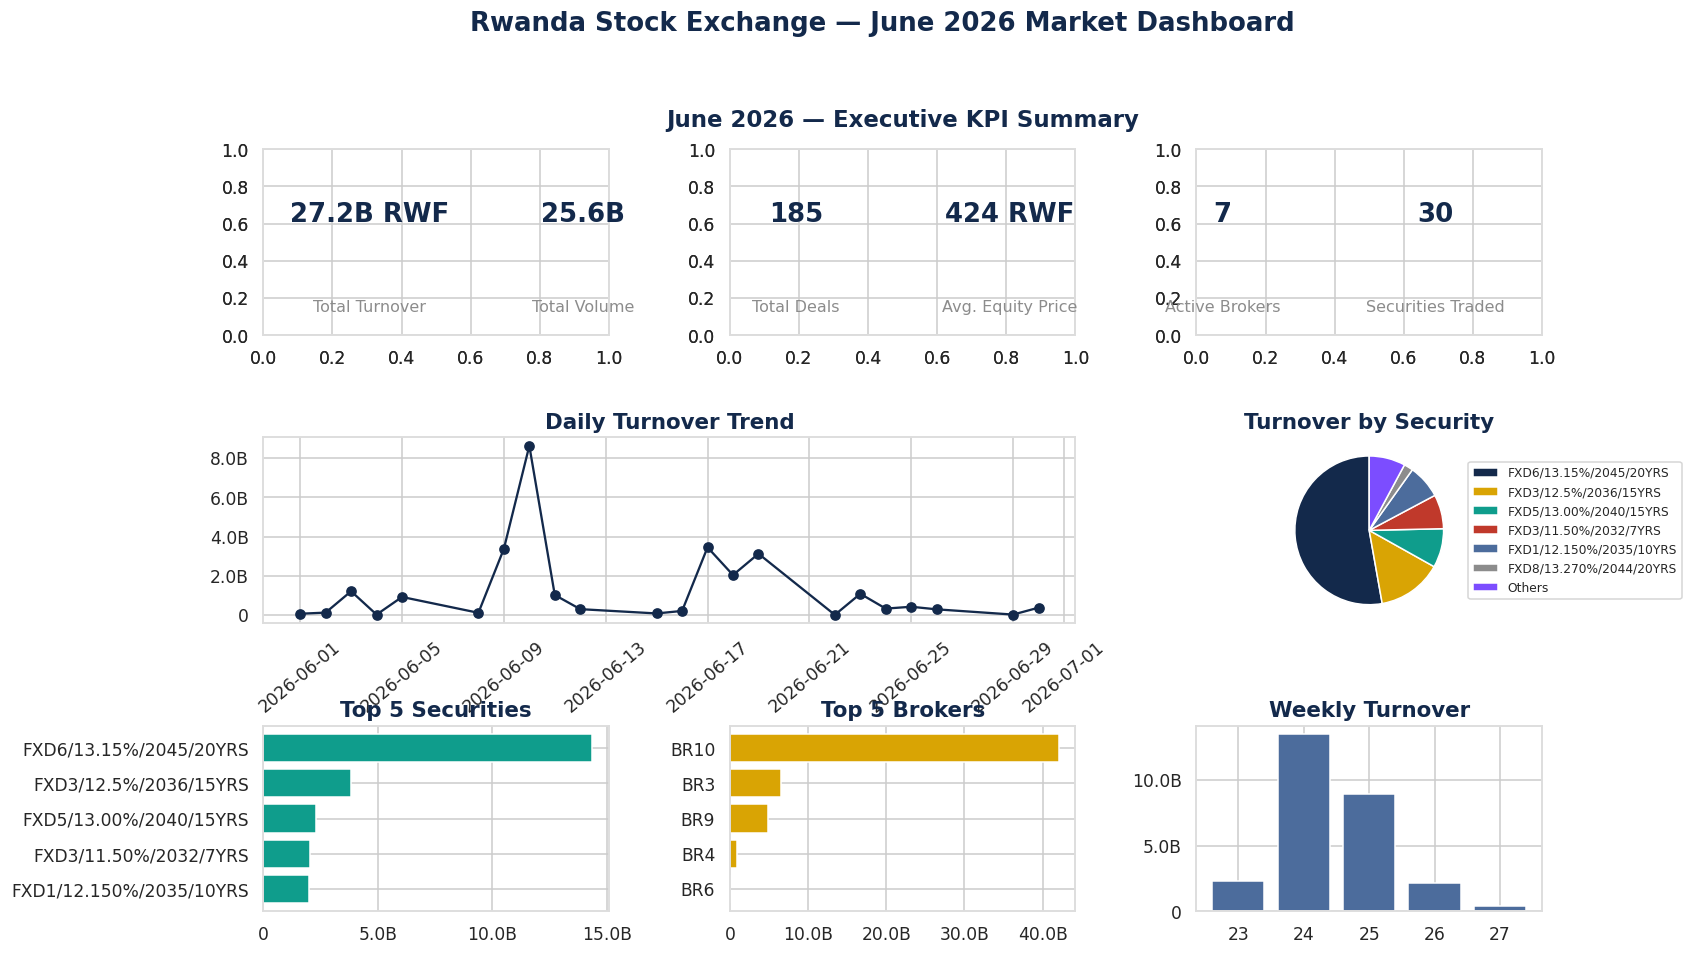

In [22]:

total_turnover = df["Turnover"].sum()
total_volume = df["Quantity"].sum()
total_deals = int(df["Deals"].sum())
avg_price_eq = equities["Price"].mean()
n_brokers = pd.concat([df["Buyer Code"], df["Seller Code"]]).nunique()
n_secs = df["Security"].nunique()

fig = plt.figure(figsize=(15, 9))
gs = fig.add_gridspec(3, 3, hspace=0.55, wspace=0.35)

# KPI cards (top row)
kpis = [
    ("Total Turnover", rwf(total_turnover) + " RWF"),
    ("Total Volume", rwf(total_volume)),
    ("Total Deals", f"{total_deals:,}"),
    ("Avg. Equity Price", f"{avg_price_eq:,.0f} RWF"),
    ("Active Brokers", f"{n_brokers}"),
    ("Securities Traded", f"{n_secs}"),
]
for i,(label,val) in enumerate(kpis):
    ax = fig.add_subplot(gs[0, i % 3]) if i < 3 else fig.add_subplot(gs[0, i % 3])

positions = [(0,0),(0,1),(0,2)]
# Use a dedicated row of 3 axes for first 3 KPIs, then reuse same row conceptually with a 2nd figure below
axK = fig.add_subplot(gs[0, :])
axK.axis("off")
n = len(kpis)
for i,(label,val) in enumerate(kpis):
    x = (i + 0.5) / n
    axK.text(x, 0.65, val, ha="center", va="center", fontsize=17, fontweight="bold", color=NAVY, transform=axK.transAxes)
    axK.text(x, 0.15, label, ha="center", va="center", fontsize=10.5, color=GRAY, transform=axK.transAxes)
axK.set_title("June 2026 — Executive KPI Summary", fontsize=15, color=NAVY, fontweight="bold", pad=15)

ax1 = fig.add_subplot(gs[1, 0:2])
ax1.plot(daily_sorted["Posting Date"], daily_sorted["Turnover"], color=NAVY, marker="o")
ax1.set_title("Daily Turnover Trend")
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(rwf))
ax1.tick_params(axis="x", rotation=40)

ax2 = fig.add_subplot(gs[1, 2])
ax2.pie(share_values, labels=None, colors=PALETTE, startangle=90)
ax2.set_title("Turnover by Security")
ax2.legend(share_labels, loc="center left", bbox_to_anchor=(1,0.5), fontsize=8)

ax3 = fig.add_subplot(gs[2, 0])
top5sec = sec_perf.head(5).iloc[::-1]
ax3.barh(top5sec["Security"], top5sec["Turnover"], color=TEAL)
ax3.set_title("Top 5 Securities")
ax3.xaxis.set_major_formatter(mticker.FuncFormatter(rwf))

ax4 = fig.add_subplot(gs[2, 1])
top5br = broker.sort_values("Total_Turnover", ascending=False).head(5).iloc[::-1]
ax4.barh(top5br.index, top5br["Total_Turnover"], color=GOLD)
ax4.set_title("Top 5 Brokers")
ax4.xaxis.set_major_formatter(mticker.FuncFormatter(rwf))

ax5 = fig.add_subplot(gs[2, 2])
ax5.bar(weekly["Week"].astype(str), weekly["Turnover"], color=LBLUE)
ax5.set_title("Weekly Turnover")
ax5.yaxis.set_major_formatter(mticker.FuncFormatter(rwf))

plt.suptitle("Rwanda Stock Exchange — June 2026 Market Dashboard", fontsize=17, fontweight="bold", color=NAVY, y=1.02)
plt.show()


## 18. Summary of Key Insights & Recommendations

1. **Concentration is the defining feature of this market.** A small number of securities and a small
   number of brokers account for the large majority of turnover (Sections 5, 9, 13). RSE could
   consider incentives to broaden participation across more listings and member firms.
2. **Bonds vs. equities behave differently.** Bonds drive most RWF turnover through large block
   trades, while equities generate more frequent, smaller deals (Sections 8, 11). Any single
   "market turnover" headline number should be read alongside this split.
3. **Liquidity is uneven.** Some securities trade almost daily; many bonds trade only once or twice
   a month (Section 7). These illiquid names may need market-making support.
4. **A few trading days are statistical outliers**, usually due to one or two large trades
   (Section 15) — worth a quick surveillance check to confirm they are legitimate.
5. **Month-over-month trend and moving averages** (Section 14) give an early read on momentum;
   once more months of data are available, formal forecasting (Prophet/ARIMA) becomes viable.
6. **Broker-to-broker trading patterns** (Section 16) can highlight repeat counterparty relationships,
   including potential internal crosses, that regulators may wish to review.

*This analysis is based on one month (June 2026) of trading data. Conclusions on trends, seasonality,
and volatility will become more robust as more months are added to the dataset.*
